# 04 · Timing benchmark and smoke test — run on the machine used for the full run
Times ~30 **random settings from the final search box** per model (not defaults), then estimates the full run.
If the estimate is above 6 h, lower the tree caps (XGBoost n_estimators to 500 first, then RF to 300).

In [1]:
import os
from pathlib import Path
import pandas as pd
from IPython.display import display
from hpo import config, data, spaces, starts, methods, runner, stats, plots

pd.set_option("display.precision", 5)
# Results folder: the full run by default. Set HPO_RESULTS=smoke to read the smoke test.
RESULTS = (
    config.SMOKE_DIR if os.environ.get("HPO_RESULTS") == "smoke" else config.RESULTS_DIR
)
FIGS, TABLES = RESULTS / "figures", RESULTS / "tables"
TABLES.mkdir(parents=True, exist_ok=True)
print("Reading/writing:", RESULTS.relative_to(config.ROOT))

Reading/writing: results


In [2]:
import platform, os as _os

print(platform.platform(), "| cores:", _os.cpu_count(), "| workers:", config.N_WORKERS)
bench = pd.DataFrame([r for m in config.MODELS for r in runner.benchmark(m, n=30)])
config.RESULTS_DIR.mkdir(parents=True, exist_ok=True)
bench.to_csv(config.RESULTS_DIR / "timing.csv", index=False)
bench.groupby("model")["fit_s"].describe()[["mean", "50%", "max"]]

macOS-15.8.1-arm64-arm-64bit | cores: 14 | workers: 10


,mean,50%,max
model,,,
rf,0.70910,0.56020,1.87098
svm,0.33681,0.24626,1.90132
xgb,0.18439,0.17638,0.40791


In [3]:
est = runner.estimate_hours(bench.groupby("model")["fit_s"].mean().to_dict())
print(f"Fits per model: {est['fits_per_model']:,}")
print("Core-hours per model:", {k: round(v, 1) for k, v in est["core_hours"].items()})
print(f"Estimated wall-clock: {est['wall_hours']:.1f} h on {config.N_WORKERS} workers")
print(
    "FALLBACK NEEDED (lower tree caps)"
    if est["fallback_needed"]
    else "No fallback needed"
)

Fits per model: 25,600
Core-hours per model: {'rf': 5.0, 'svm': 2.4, 'xgb': 1.3}
Estimated wall-clock: 1.0 h on 10 workers
No fallback needed


## Fit-time distribution (spots slow corners: large C, many deep trees)

,model,fit_s,auc,C,gamma,n_estimators,max_depth,min_samples_split,max_features,learning_rate,subsample,colsample_bytree
3,svm,1.90132,0.78968,11322.46109,0.00096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
37,rf,1.87098,0.82439,NaN,NaN,463.0,20.0,19.0,0.87822,NaN,NaN,NaN
44,rf,1.82703,0.81507,NaN,NaN,426.0,20.0,7.0,0.82992,NaN,NaN,NaN
52,rf,1.71661,0.82440,NaN,NaN,454.0,12.0,17.0,0.81896,NaN,NaN,NaN
47,rf,1.43821,0.82238,NaN,NaN,476.0,15.0,11.0,0.56720,NaN,NaN,NaN


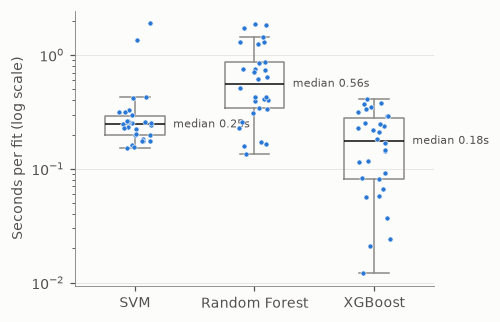

In [4]:
fig = plots.fig_fit_times(bench)
plots.save(fig, config.RESULTS_DIR / "figures", "nb04_fit_times")
bench.sort_values("fit_s", ascending=False).head(5)

## Smoke test: real models, B = 20, seeds 0–1, all 5 methods → `results/smoke/`

In [5]:
runner.run_all(
    out_dir=config.SMOKE_DIR, budget=20, seeds=[0, 1], n_workers=config.N_WORKERS
)
smoke, _ = stats.load(config.SMOKE_DIR)
print(stats.check_runs(smoke))

30 runs already done, 0 to go, 10 workers
{'runs': 30, 'all_full_budget': True, 'budget': 20, 'duplicates': 0, 'per_model_method': {'de': {'rf': 2, 'svm': 2, 'xgb': 2}, 'ga': {'rf': 2, 'svm': 2, 'xgb': 2}, 'grid': {'rf': 2, 'svm': 2, 'xgb': 2}, 'pso': {'rf': 2, 'svm': 2, 'xgb': 2}, 'random': {'rf': 2, 'svm': 2, 'xgb': 2}}}
